<a href="https://colab.research.google.com/github/ritigya03/cardiotrust-dashboard/blob/main/Another_copy_of_BTP_CardioTrust.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

print("Google Drive mounted at /content/drive")
print("You can now access your Google Drive files in this path.")

!pip install opacus web3 -q

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted at /content/drive
You can now access your Google Drive files in this path.


In [ ]:

from google.colab import files
uploaded = files.upload()  # Upload blockchain.py and api.py

Saving blockchain.py to blockchain (2).py


In [ ]:

%%writefile blockchain.py
import os
import hashlib
import secrets
import torch
import torch.nn as nn
from web3 import Web3
import time

# Contract configuration - UPDATED ADDRESS
CONTRACT_ADDRESS = "0x845460bC4fcc217e218402472ad0959764fb32B5"
RPC_URL = "https://ethereum-sepolia-rpc.publicnode.com"
PRIVATE_KEY = "0xae7935d459b0087dad41622fb2df4e91a42914078fd4075168568fd4c6ba2c30"

# Clean ABI – matches your deployed CardioTrustFL v3 contract
CONTRACT_ABI = [
    {"type":"constructor","inputs":[],"stateMutability":"nonpayable"},
    {"type":"function","name":"registerHospital","inputs":[{"name":"addr","type":"address"},{"name":"name","type":"string"}],"outputs":[],"stateMutability":"nonpayable"},
    {"type":"function","name":"deactivateHospital","inputs":[{"name":"addr","type":"address"},{"name":"reason","type":"string"}],"outputs":[],"stateMutability":"nonpayable"},
    {"type":"function","name":"setThresholds","inputs":[{"name":"_minReputation","type":"uint256"},{"name":"_commitThresholdPct","type":"uint256"},{"name":"_consensusThresholdPct","type":"uint256"}],"outputs":[],"stateMutability":"nonpayable"},
    {"type":"function","name":"startNewRound","inputs":[],"outputs":[],"stateMutability":"nonpayable"},
    {"type":"function","name":"commitUpdate","inputs":[{"name":"commitHash","type":"bytes32"}],"outputs":[],"stateMutability":"nonpayable"},
    {"type":"function","name":"revealUpdate","inputs":[{"name":"localModelHash","type":"bytes32"},{"name":"epsilonScaled","type":"uint256"},{"name":"sampleCount","type":"uint256"},{"name":"salt","type":"bytes32"}],"outputs":[],"stateMutability":"nonpayable"},
    {"type":"function","name":"voteOnAggregation","inputs":[{"name":"proposedGlobalHash","type":"bytes32"}],"outputs":[],"stateMutability":"nonpayable"},
    {"type":"function","name":"getActiveCount","inputs":[],"outputs":[{"name":"","type":"uint256"}],"stateMutability":"view"},
    {"type":"function","name":"currentRound","inputs":[],"outputs":[{"name":"","type":"uint256"}],"stateMutability":"view"},
    {"type":"function","name":"roundFinalized","inputs":[],"outputs":[{"name":"","type":"bool"}],"stateMutability":"view"},
    {"type":"function","name":"commitCountPerRound","inputs":[{"name":"","type":"uint256"}],"outputs":[{"name":"","type":"uint256"}],"stateMutability":"view"},
    {"type":"function","name":"revealCountPerRound","inputs":[{"name":"","type":"uint256"}],"outputs":[{"name":"","type":"uint256"}],"stateMutability":"view"},
    {"type":"function","name":"weightedVoteCount","inputs":[{"name":"","type":"uint256"},{"name":"","type":"bytes32"}],"outputs":[{"name":"","type":"uint256"}],"stateMutability":"view"},
    {"type":"function","name":"globalModels","inputs":[{"name":"","type":"uint256"}],"outputs":[{"name":"globalModelHash","type":"bytes32"},{"name":"round","type":"uint256"},{"name":"timestamp","type":"uint256"},{"name":"participantCount","type":"uint256"},{"name":"totalWeightedVotes","type":"uint256"},{"name":"avgEpsilonScaled","type":"uint256"}],"stateMutability":"view"},
    {"type":"function","name":"getHospital","inputs":[{"name":"addr","type":"address"}],"outputs":[{"name":"","type":"tuple","components":[{"name":"id","type":"uint256"},{"name":"addr","type":"address"},{"name":"name","type":"string"},{"name":"isActive","type":"bool"},{"name":"joinedAt","type":"uint256"},{"name":"totalSubmissions","type":"uint256"},{"name":"totalSampleCount","type":"uint256"},{"name":"missedRounds","type":"uint256"},{"name":"reputationScore","type":"uint256"},{"name":"lastRound","type":"uint256"}]}],"stateMutability":"view"},
    {"type":"function","name":"getLocalUpdate","inputs":[{"name":"round","type":"uint256"},{"name":"addr","type":"address"}],"outputs":[{"name":"","type":"tuple","components":[{"name":"localModelHash","type":"bytes32"},{"name":"epsilonScaled","type":"uint256"},{"name":"sampleCount","type":"uint256"},{"name":"timestamp","type":"uint256"},{"name":"verified","type":"bool"}]}],"stateMutability":"view"},
    {"type":"function","name":"getRoundStatus","inputs":[],"outputs":[{"name":"round","type":"uint256"},{"name":"finalized","type":"bool"},{"name":"commits","type":"uint256"},{"name":"reveals","type":"uint256"},{"name":"activeHospitals","type":"uint256"}],"stateMutability":"view"},
    {"type":"function","name":"computeCommitHash","inputs":[{"name":"localModelHash","type":"bytes32"},{"name":"epsilonScaled","type":"uint256"},{"name":"salt","type":"bytes32"}],"outputs":[{"name":"","type":"bytes32"}],"stateMutability":"pure"},
    {"type":"function","name":"hospitalById","inputs":[{"name":"","type":"uint256"}],"outputs":[{"name":"","type":"address"}],"stateMutability":"view"},
    {"type":"function","name":"claimReward","inputs":[{"name":"round","type":"uint256"}],"outputs":[],"stateMutability":"nonpayable"},
    {"type":"function","name":"claimMissedRoundPenalty","inputs":[{"name":"round","type":"uint256"}],"outputs":[],"stateMutability":"nonpayable"},
    {"type":"function","name":"rewardClaimed","inputs":[{"name":"","type":"uint256"},{"name":"","type":"address"}],"outputs":[{"name":"","type":"bool"}],"stateMutability":"view"},
    {"type":"function","name":"penaltyApplied","inputs":[{"name":"","type":"uint256"},{"name":"","type":"address"}],"outputs":[{"name":"","type":"bool"}],"stateMutability":"view"},
    {"type":"function","name":"totalWeightedVotesCast","inputs":[{"name":"","type":"uint256"}],"outputs":[{"name":"","type":"uint256"}],"stateMutability":"view"},
    {"type":"function","name":"getTotalPossibleWeight","inputs":[{"name":"round","type":"uint256"}],"outputs":[{"name":"","type":"uint256"}],"stateMutability":"view"},
    {"type":"function","name":"aggVotes","inputs":[{"name":"","type":"uint256"},{"name":"","type":"address"}],"outputs":[{"name":"proposedGlobalHash","type":"bytes32"},{"name":"weightedVote","type":"uint256"},{"name":"timestamp","type":"uint256"}],"stateMutability":"view"},
    {"type":"function","name":"commitments","inputs":[{"name":"","type":"uint256"},{"name":"","type":"address"}],"outputs":[{"name":"commitHash","type":"bytes32"},{"name":"timestamp","type":"uint256"},{"name":"exists","type":"bool"}],"stateMutability":"view"},
    {"type":"function","name":"localUpdates","inputs":[{"name":"","type":"uint256"},{"name":"","type":"address"}],"outputs":[{"name":"localModelHash","type":"bytes32"},{"name":"epsilonScaled","type":"uint256"},{"name":"sampleCount","type":"uint256"},{"name":"timestamp","type":"uint256"},{"name":"verified","type":"bool"}],"stateMutability":"view"},
    {"type":"function","name":"hospitals","inputs":[{"name":"","type":"address"}],"outputs":[{"name":"id","type":"uint256"},{"name":"addr","type":"address"},{"name":"name","type":"string"},{"name":"isActive","type":"bool"},{"name":"joinedAt","type":"uint256"},{"name":"totalSubmissions","type":"uint256"},{"name":"totalSampleCount","type":"uint256"},{"name":"missedRounds","type":"uint256"},{"name":"reputationScore","type":"uint256"},{"name":"lastRound","type":"uint256"}],"stateMutability":"view"}
]

class BlockchainClient:
    def __init__(self, private_key: str = PRIVATE_KEY, rpc_url: str = RPC_URL):
        self.w3 = Web3(Web3.HTTPProvider(rpc_url))
        if not self.w3.is_connected():
            raise ConnectionError("Failed to connect to Sepolia")
        self.account = self.w3.eth.account.from_key(private_key)
        self.address = self.account.address
        self.private_key = private_key
        self.contract = self.w3.eth.contract(
            address=Web3.to_checksum_address(CONTRACT_ADDRESS),
            abi=CONTRACT_ABI
        )
        print(f"Connected to Sepolia")
        print(f"Wallet address : {self.address}")
        print(f"Contract       : {CONTRACT_ADDRESS}")
        self._round_salts = {}

    @staticmethod
    def compute_model_hash(model_or_weights) -> bytes:
        if isinstance(model_or_weights, nn.Module):
            data = b"".join(p.data.cpu().numpy().tobytes() for p in model_or_weights.parameters())
            return hashlib.sha256(data).digest()
        elif isinstance(model_or_weights, list):
            data = b"".join(arr.tobytes() if hasattr(arr, 'tobytes') else bytes(arr) for arr in model_or_weights)
            return hashlib.sha256(data).digest()
        else:
            return hashlib.sha256(str(model_or_weights).encode()).digest()

    @staticmethod
    def _scale_epsilon(epsilon: float) -> int:
        return int(epsilon * 10000)

    @staticmethod
    def _generate_salt() -> bytes:
        return secrets.token_bytes(32)

    def _send_transaction(self, func, gas_limit: int = 300000, gas_price_multiplier: int = 1):
        try:
            nonce = self.w3.eth.get_transaction_count(self.address, 'latest')
            base_gas_price = self.w3.eth.gas_price
            gas_price = int(base_gas_price * gas_price_multiplier)
            try:
                estimated = func.estimate_gas({"from": self.address})
                gas_limit = max(estimated + 20000, gas_limit)
            except Exception as e:
                print(f"  Gas estimation warning: {e}")
            tx = func.build_transaction({
                "from": self.address,
                "nonce": nonce,
                "gas": gas_limit,
                "gasPrice": gas_price,
                "chainId": 11155111,
            })
            signed = self.w3.eth.account.sign_transaction(tx, self.account.key)
            raw_tx = getattr(signed, 'raw_transaction', None) or getattr(signed, 'rawTransaction', None)
            tx_hash = self.w3.eth.send_raw_transaction(raw_tx)
            print(f"  TX sent: {tx_hash.hex()}")
            receipt = self.w3.eth.wait_for_transaction_receipt(tx_hash, timeout=180)
            if receipt['status'] == 1:
                print(f"  ✅ Confirmed in block {receipt['blockNumber']}")
                return receipt
            else:
                try:
                    self.w3.eth.call(tx)
                except Exception as call_err:
                    print(f"  ❌ Failed: {call_err}")
                return None
        except Exception as e:
            print(f"  ❌ TX error: {str(e)[:100]}")
            return None

    def start_new_round(self):
        cur = self.get_current_round()
        fin = self.is_round_finalized()
        if cur > 0 and not fin:
            print(f"  ⚠️ Round {cur} not finalized. Cannot start new round.")
            return None
        print(f"\n⛓ Starting new round...")
        func = self.contract.functions.startNewRound()
        receipt = self._send_transaction(func, gas_limit=300000)
        if receipt:
            new_round = self.get_current_round()
            print(f"  ✅ Round {new_round} started")
        return receipt

    def commit_update(self, commit_hash: bytes):
        """Submit a commitment hash."""
        print(f"\n🔐 Committing update...")
        func = self.contract.functions.commitUpdate(commit_hash)
        return self._send_transaction(func, gas_limit=200000)

    def reveal_update(self, local_model_hash: bytes, epsilon_scaled: int, sample_count: int, salt: bytes):
        """Reveal the local model update with sample count."""
        print(f"\n📤 Revealing update...")
        func = self.contract.functions.revealUpdate(local_model_hash, epsilon_scaled, sample_count, salt)
        return self._send_transaction(func, gas_limit=200000)

    def vote_on_aggregation(self, proposed_hash: bytes):
        """Vote on the aggregated global model. Use bytes([0])*32 for NO vote."""
        print(f"\n🗳️ Voting on aggregation...")
        func = self.contract.functions.voteOnAggregation(proposed_hash)
        return self._send_transaction(func, gas_limit=200000)

    def vote_no(self):
        """Vote 'no' on the current round (reject the proposed global model)."""
        zero_hash = bytes([0]) * 32
        return self.vote_on_aggregation(zero_hash)

    def get_vote_count(self, round_num: int, hash_value: bytes) -> int:
        return self.contract.functions.weightedVoteCount(round_num, hash_value).call()

    def register_hospital(self, hospital_address: str, name: str):
        print(f"\n🏥 Registering hospital: {name}")
        func = self.contract.functions.registerHospital(
            Web3.to_checksum_address(hospital_address), name
        )
        return self._send_transaction(func, gas_limit=300000)

    def claim_reward(self, round_num: int):
        """Claim reward for participating in a finalized round."""
        print(f"\n💰 Claiming reward for round {round_num}...")
        func = self.contract.functions.claimReward(round_num)
        return self._send_transaction(func, gas_limit=200000)

    def claim_penalty(self, round_num: int):
        """Claim penalty for missing a round."""
        print(f"\n⚠️ Claiming penalty for round {round_num}...")
        func = self.contract.functions.claimMissedRoundPenalty(round_num)
        return self._send_transaction(func, gas_limit=200000)

    def get_current_round(self) -> int:
        try:
            return self.contract.functions.currentRound().call()
        except:
            return 0

    def get_active_hospital_count(self) -> int:
        try:
            return self.contract.functions.getActiveCount().call()
        except:
            return 0

    def is_round_finalized(self) -> bool:
        try:
            return self.contract.functions.roundFinalized().call()
        except:
            return False

    def get_commit_count(self, round_num: int = None) -> int:
        if round_num is None:
            round_num = self.get_current_round()
        try:
            return self.contract.functions.commitCountPerRound(round_num).call()
        except:
            return 0

    def get_reveal_count(self, round_num: int = None) -> int:
        if round_num is None:
            round_num = self.get_current_round()
        try:
            return self.contract.functions.revealCountPerRound(round_num).call()
        except:
            return 0

    def get_hospital(self, addr: str):
        return self.contract.functions.getHospital(addr).call()

    def get_total_possible_weight(self, round_num: int) -> int:
        try:
            return self.contract.functions.getTotalPossibleWeight(round_num).call()
        except:
            return 0

    def get_round_status(self):
        return self.contract.functions.getRoundStatus().call()

    def print_round_status(self):
        cur = self.get_current_round()
        fin = self.is_round_finalized()
        commits = self.get_commit_count(cur)
        reveals = self.get_reveal_count(cur)
        active = self.get_active_hospital_count()
        print(f"\n{'='*40}")
        print(f"  Current Round    : {cur}")
        print(f"  Round Finalized  : {fin}")
        print(f"  Commits          : {commits} / {active}")
        print(f"  Reveals          : {reveals} / {active}")
        print(f"{'='*40}")

Overwriting blockchain.py


In [ ]:
import sys
import importlib

# Remove the cached blockchain module
if 'blockchain' in sys.modules:
    del sys.modules['blockchain']
    print("✅ Removed cached blockchain module")

# Import fresh
from blockchain import BlockchainClient

# Create client with explicit private key (the new contract address is now in the file)
bc = BlockchainClient(
    private_key="0xae7935d459b0087dad41622fb2df4e91a42914078fd4075168568fd4c6ba2c30",
    rpc_url="https://ethereum-sepolia-rpc.publicnode.com"
)

print(f"Contract address: {bc.contract.address}")
print(f"Current round: {bc.get_current_round()}")

✅ Removed cached blockchain module
Connected to Sepolia
Wallet address : 0x5Bf8Ae260FD33f5423C0e3e7457118162B9C5414
Contract       : 0x845460bC4fcc217e218402472ad0959764fb32B5
Contract address: 0x845460bC4fcc217e218402472ad0959764fb32B5
Current round: 0


In [ ]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Load data
file_path = '/content/drive/MyDrive/BTP/Heart_disease_cleveland_new.csv'
df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

# Prepare features and target
X_fresh = df.drop(columns=['target'])
y_fresh = df['target']

# Scale features
scaler_mlp = StandardScaler()
X_scaled = scaler_mlp.fit_transform(X_fresh)

# Split data
X_tr, X_te, y_tr, y_te = train_test_split(
    X_scaled, y_fresh.values,
    test_size=0.2, random_state=42, stratify=y_fresh
)

print(f"Training set: {X_tr.shape[0]} samples")
print(f"Test set: {X_te.shape[0]} samples")
print(f"Input dimension: {X_tr.shape[1]}")

Dataset shape: (303, 14)
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
Training set: 242 samples
Test set: 61 samples
Input dimension: 13


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# Random Forest baseline
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_tr, y_tr)
y_pred_rf = rf.predict(X_te)

print("Random Forest Results:")
print(f"  Accuracy: {accuracy_score(y_te, y_pred_rf):.4f}")
print(f"  F1 Score: {f1_score(y_te, y_pred_rf):.4f}")

Random Forest Results:
  Accuracy: 0.9016
  F1 Score: 0.9000


In [ ]:
bc_owner = BlockchainClient(
    private_key="0xae7935d459b0087dad41622fb2df4e91a42914078fd4075168568fd4c6ba2c30",
    rpc_url="https://ethereum-sepolia-rpc.publicnode.com"
)

Connected to Sepolia
Wallet address : 0x5Bf8Ae260FD33f5423C0e3e7457118162B9C5414
Contract       : 0x845460bC4fcc217e218402472ad0959764fb32B5


In [ ]:
from blockchain import BlockchainClient
import time

bc_owner = BlockchainClient(
    private_key="0xae7935d459b0087dad41622fb2df4e91a42914078fd4075168568fd4c6ba2c30",
    rpc_url="https://ethereum-sepolia-rpc.publicnode.com"
)

hospital_addresses = [
    "0x5Bf8Ae260FD33f5423C0e3e7457118162B9C5414",   # H1
    "0x616f3FD764E8380c7AA76AE64fB42a9B54a55Fc1",   # H2
    "0x50517277FAB527EcFD4c9610E1C8C6C365800597",   # H3
    "0xD6B036e7841D6a5EdcC3E416d69A38a855A7130E",   # H4
    "0x7468eb83949745D6348612Dd32122F5f93220171"    # H5
]
names = ["H1", "H2", "H3", "H4", "H5"]

print("="*50)
print("Registering 5 hospitals on NEW contract")
print("="*50)

for addr, name in zip(hospital_addresses, names):
    print(f"\n📝 Registering {name} ({addr})...")
    receipt = bc_owner.register_hospital(addr, name)
    if receipt:
        print(f"✅ {name} registered successfully")
    else:
        print(f"❌ Failed to register {name}")
    time.sleep(2)

print("\n" + "="*50)
print("REGISTRATION COMPLETE")
print("="*50)

active_count = bc_owner.get_active_hospital_count()
print(f"Active hospitals: {active_count}")

bc_owner.print_round_status()

Connected to Sepolia
Wallet address : 0x5Bf8Ae260FD33f5423C0e3e7457118162B9C5414
Contract       : 0x845460bC4fcc217e218402472ad0959764fb32B5
Registering 5 hospitals on NEW contract

📝 Registering H1 (0x5Bf8Ae260FD33f5423C0e3e7457118162B9C5414)...

🏥 Registering hospital: H1
  TX sent: 36bc2a71dd4f13a8b2a86a42ab52847a18915485be7187cc567d0903c47b7dee
  ✅ Confirmed in block 10769218
✅ H1 registered successfully

📝 Registering H2 (0x616f3FD764E8380c7AA76AE64fB42a9B54a55Fc1)...

🏥 Registering hospital: H2
  TX sent: 01963d231d91bcaf0dc96e6ce4808828e5cdf09aa7bd263c6bbb486cb07616cb
  ✅ Confirmed in block 10769220
✅ H2 registered successfully

📝 Registering H3 (0x50517277FAB527EcFD4c9610E1C8C6C365800597)...

🏥 Registering hospital: H3
  TX sent: abb264c06b111371c39ef66629bbe5089f3285d2f25065f686312dcbe1776fb4
  ✅ Confirmed in block 10769222
✅ H3 registered successfully

📝 Registering H4 (0xD6B036e7841D6a5EdcC3E416d69A38a855A7130E)...

🏥 Registering hospital: H4
  TX sent: c3382fdd1d498b6ab5223

In [ ]:
cur = bc_owner.contract.functions.currentRound().call()
commits = bc_owner.contract.functions.commitCountPerRound(cur).call()
reveals = bc_owner.contract.functions.revealCountPerRound(cur).call()
print(f"Round {cur}, commits={commits}, reveals={reveals}")

Round 0, commits=0, reveals=0


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Connected to Sepolia
Wallet address : 0x5Bf8Ae260FD33f5423C0e3e7457118162B9C5414
Contract       : 0x845460bC4fcc217e218402472ad0959764fb32B5
Connected to Sepolia
Wallet address : 0x616f3FD764E8380c7AA76AE64fB42a9B54a55Fc1
Contract       : 0x845460bC4fcc217e218402472ad0959764fb32B5
Connected to Sepolia
Wallet address : 0x50517277FAB527EcFD4c9610E1C8C6C365800597
Contract       : 0x845460bC4fcc217e218402472ad0959764fb32B5
Connected to Sepolia
Wallet address : 0xD6B036e7841D6a5EdcC3E416d69A38a855A7130E
Contract       : 0x845460bC4fcc217e218402472ad0959764fb32B5
Connected to Sepolia
Wallet address : 0x7468eb83949745D6348612Dd32122F5f93220171
Contract       : 0x845460bC4fcc217e218402472ad0959764fb32B5
Hospital data sizes and balance weights:
  H1: 81 patients (pos=70, neg=11) → balance_weight=11
  H2: 15 patients (pos=7, neg=8) → balance_weight=7
  H3: 21 patients 

/tmp/ipykernel_33531/180782588.py:323: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  train_labels  = y_full[[train_ds.indices]].numpy().flatten()


Starting Round 1 on-chain...
    ✅ TX: 07e109db2484d11f36a3...

  ROUND 1/10

  [Step 1] Local training...
    Training H1...


/usr/local/lib/python3.12/dist-packages/opacus/privacy_engine.py:96: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
/tmp/ipykernel_33531/180782588.py:160: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  (loss + mu * prox).backward()


    H1: ε=5.85, balance_w=11
    Training H2...
    H2: ε=7.01, balance_w=7


...

    Training H3...
    H3: ε=7.01, balance_w=7
    Training H4...
    H4: ε=4.90, balance_w=1
    Training H5...
    H5: ε=7.01, balance_w=17

  [Step 2] Anomaly detection...
    No anomalies.

  [Step 3] Commit...
    H1 committing...
    ✅ TX: 1999a2e53a548afb296c...
    H2 committing...
    ✅ TX: 60d2669544444f3e57c9...
    H3 committing...
    ✅ TX: 997d0b37a23bc310535b...
    H4 committing...
    ✅ TX: bebae79f861002c50c1f...
    H5 committing...
    ✅ TX: 4c070a71d98c7f697dfd...

  [Step 4] Reveal...
    H1 revealing...
    ✅ TX: d9137c1159b223878fa5...
    H2 revealing...
    ✅ TX: b6dd17015ae7ff56b5d2...
    H3 revealing...
    ✅ TX: c9dc653007ba70d712b3...
    H4 revealing...
    ✅ TX: 9516574c6d28a2959754...
    H5 revealing...
    ✅ TX: 3ad08e161ea47684a7cc...

  [Step 5] Aggregation (balance-weighted FedAvg)...
    Aggregation weights: {'H1': 11, 'H2': 7, 'H3': 7, 'H4': 1, 'H5': 17}

  [Step 6] Voting...
    H1: prev=0.8235 → new=0.8235 → YES
    ✅ TX: a9e7352d33ada9ca4a4b.

/usr/local/lib/python3.12/dist-packages/opacus/privacy_engine.py:96: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(
/tmp/ipykernel_33531/180782588.py:160: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  (loss + mu * prox).backward()


    H1: ε=5.85, balance_w=11
    Training H2...
    H2: ε=7.01, balance_w=7


/usr/local/lib/python3.12/dist-packages/opacus/accountants/analysis/prv/prvs.py:67: RuntimeWarning: divide by zero encountered in log
  z = np.log(np.where(t > np.log(1 - q), (np.exp(t) + q - 1) / q, 1))
/usr/local/lib/python3.12/dist-packages/opacus/accountants/analysis/prv/prvs.py:70: RuntimeWarning: divide by zero encountered in log
  t > np.log(1 - q),


    Training H3...
    H3: ε=7.01, balance_w=7
    Training H4...
    H4: ε=4.90, balance_w=1
    Training H5...
    H5: ε=7.01, balance_w=17

  [Step 2] Anomaly detection...
    No anomalies.

  [Step 3] Commit...
    H1 committing...
    ✅ TX: 4f15a2bc0908668c8ac7...
    H2 committing...
    ✅ TX: 8a82a9d034a41e96c248...
    H3 committing...
    ✅ TX: 26fb77a97b78a5e3ff88...
    H4 committing...
    ✅ TX: 0381f8b1457553189e94...
    H5 committing...
    ✅ TX: ade92efc40cfc25ae2e4...

  [Step 4] Reveal...
    H1 revealing...
    ✅ TX: 077660749050414a0d7b...
    H2 revealing...
    ✅ TX: 2713facef2501e554a62...
    H3 revealing...
    ✅ TX: 12e5fa628527baa8b535...
    H4 revealing...
    ✅ TX: c6e656c07bab273f456d...
    H5 revealing...
    ✅ TX: 43900ec40b655154756d...

  [Step 5] Aggregation (balance-weighted FedAvg)...
    Aggregation weights: {'H1': 11, 'H2': 7, 'H3': 7, 'H4': 1, 'H5': 17}

  [Step 6] Voting...
    H1: prev=0.8235 → new=0.8235 → YES
    ✅ TX: 924dfdcc7624cbccdcb7.

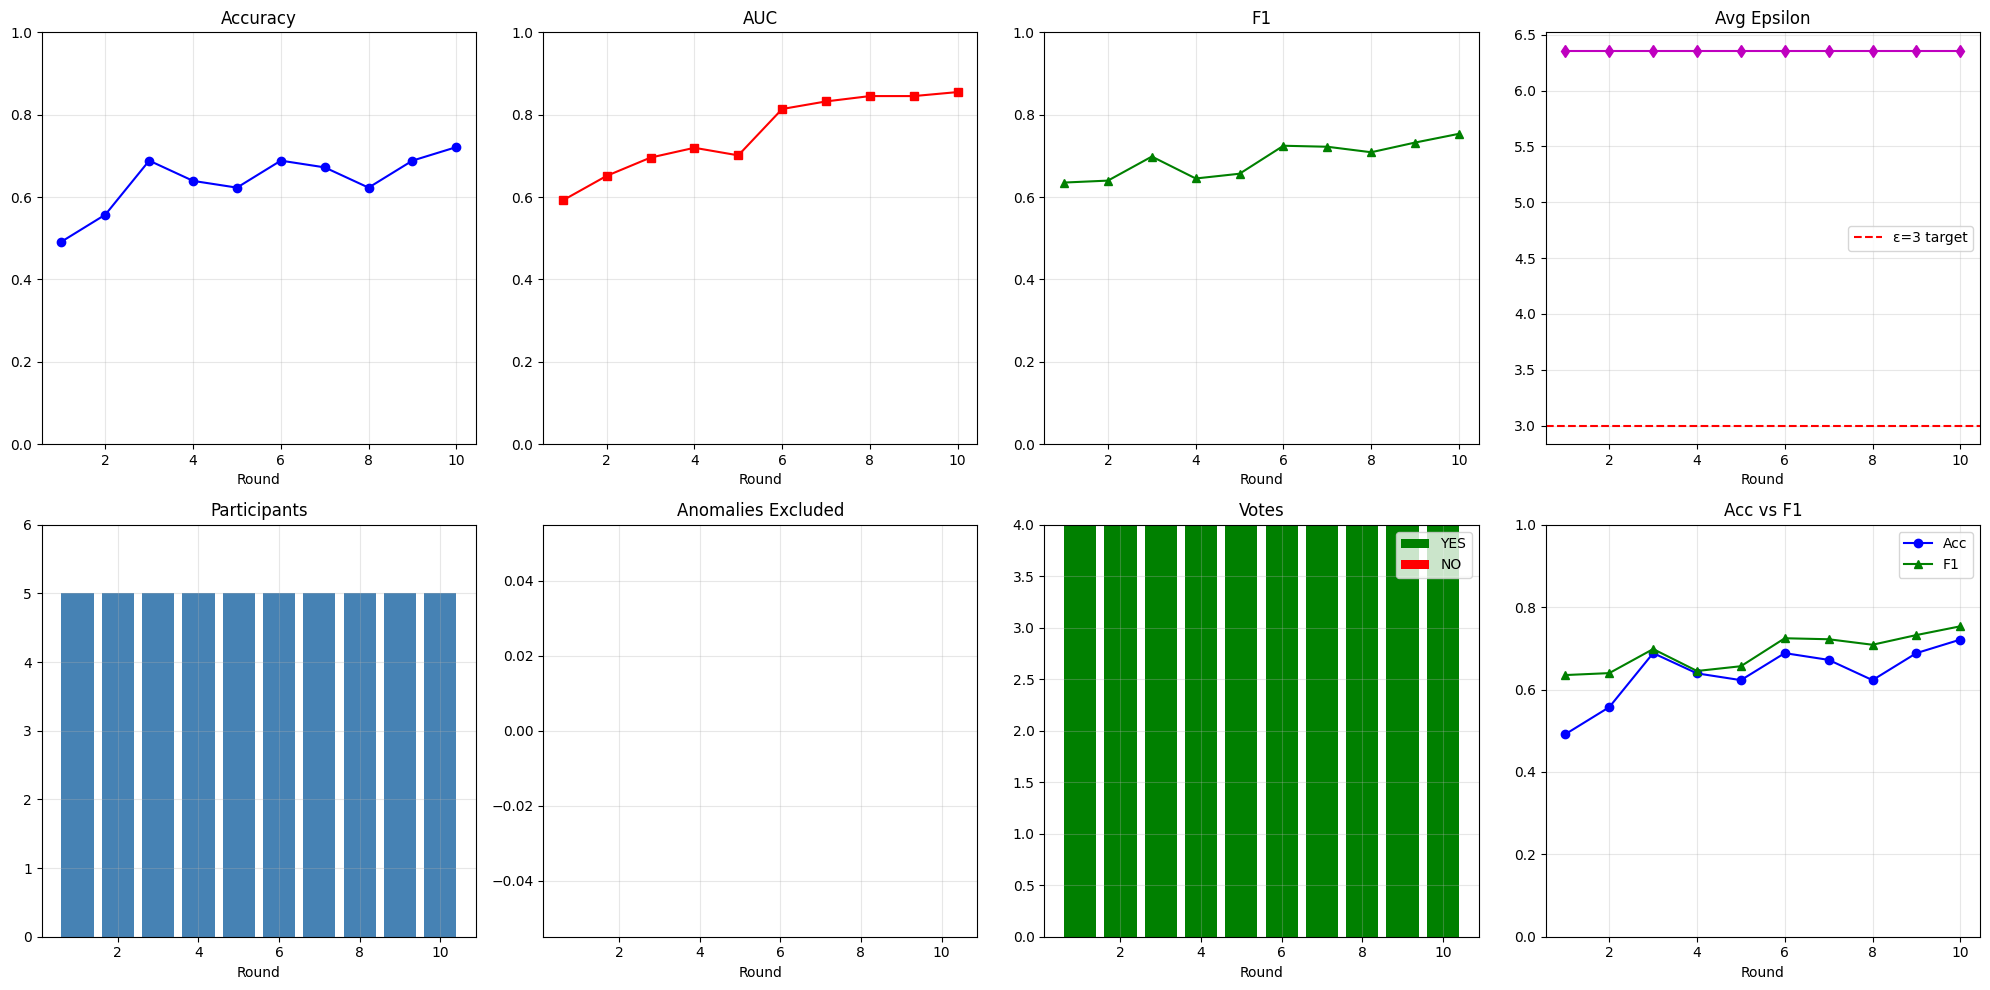


✅ Plot saved.

✅ Done.


In [ ]:
# ============================================================
# CARDIOTRUST FL v3 – AGGREGATION FIX
# Root cause of stagnation:
#   H4 (89 samples, 1 positive) dominates weighted FedAvg
#   and collapses the global model to predict all-negative.
#   Fix: weight by min(pos_count, neg_count) instead of
#        total sample count — rewards balanced local data.
# Also removed random noise injection (was corrupting weights).
# ============================================================

import os, csv, time, signal, secrets
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, random_split, WeightedRandomSampler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import matplotlib.pyplot as plt
from web3 import Web3
from opacus import PrivacyEngine
from google.colab import drive

drive.mount('/content/drive')

RESULTS_CSV = '/content/drive/MyDrive/cardiotrust_fl_v3_agg_fix.csv'
if not os.path.exists(RESULTS_CSV):
    with open(RESULTS_CSV, 'w', newline='') as f:
        csv.writer(f).writerow(['round','accuracy','f1','auc',
                                'avg_epsilon','participants','anomalies',
                                'yes_votes','no_votes'])

# ─────────────────────────────────────────────
#  MODEL
# ─────────────────────────────────────────────
class HeartDiseaseNet(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 32),        nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(32, 16),        nn.ReLU(),
            nn.Linear(16, 1)          # raw logits — sigmoid applied at eval
        )
    def forward(self, x):
        return self.network(x)

def get_weights(model):
    return [v.cpu().detach().numpy().copy() for v in model.state_dict().values()]

def set_weights(model, weights):
    sd = model.state_dict()
    with torch.no_grad():
        for (k, _), w in zip(sd.items(), weights):
            sd[k] = torch.tensor(w)
    model.load_state_dict(sd)

def hash_weights(weights):
    import hashlib
    h = hashlib.sha3_256()
    for w in weights:
        h.update(np.array(w).tobytes())
    return bytes.fromhex(h.hexdigest())

# ─────────────────────────────────────────────
#  BALANCE WEIGHT
#  This is the core fix. Instead of weighting by total
#  sample count (which lets H4's 88 negatives dominate),
#  we weight by the minority class count — a hospital with
#  balanced data contributes more than one that is 98% one class.
# ─────────────────────────────────────────────
def balance_weight(y_local):
    """
    Returns min(pos_count, neg_count) as the aggregation weight.
    A hospital with 1 pos and 88 neg gets weight=1.
    A hospital with 11 pos and 70 neg gets weight=11.
    This prevents class-imbalanced hospitals from dominating.
    """
    y = np.array(y_local).flatten()
    pos = int((y == 1).sum())
    neg = int((y == 0).sum())
    return max(min(pos, neg), 1)   # at least 1 so hospital isn't excluded

# ─────────────────────────────────────────────
#  DATA PARTITION
# ─────────────────────────────────────────────
def dirichlet_split(X, y, num_clients, alpha=0.5, seed=42):
    np.random.seed(seed)
    client_indices = [[] for _ in range(num_clients)]
    for c in np.unique(y):
        c_idx = np.where(y == c)[0]
        np.random.shuffle(c_idx)
        props = np.random.dirichlet([alpha] * num_clients)
        props = (props * len(c_idx)).astype(int)
        props[-1] = len(c_idx) - props[:-1].sum()
        start = 0
        for cid, cnt in enumerate(props):
            client_indices[cid].extend(c_idx[start:start + cnt].tolist())
            start += cnt
    return client_indices

# ─────────────────────────────────────────────
#  ANOMALY DETECTION
# ─────────────────────────────────────────────
def flatten_weights(weights):
    return np.concatenate([np.array(w).flatten() for w in weights])

def detect_anomalies(all_weights, threshold=0.3):
    if len(all_weights) <= 2:
        return list(range(len(all_weights))), []
    flat = [flatten_weights(w) for w in all_weights]
    median_vec = np.median(flat, axis=0)
    median_norm = np.linalg.norm(median_vec)
    clean, anomalies = [], []
    for i, f in enumerate(flat):
        norm = np.linalg.norm(f)
        if norm == 0 or median_norm == 0:
            clean.append(i); continue
        cosine_dist = 1 - np.dot(f, median_vec) / (norm * median_norm)
        if cosine_dist <= threshold:
            clean.append(i)
        else:
            anomalies.append(i)
            print(f"    ⚠️  Hospital {i} flagged (cosine={cosine_dist:.3f})")
    return clean, anomalies

# ─────────────────────────────────────────────
#  FOCAL LOSS
# ─────────────────────────────────────────────
def focal_loss(logits, target, gamma=2.0, alpha=0.25):
    bce = nn.functional.binary_cross_entropy_with_logits(
        logits, target, reduction='none')
    probs = torch.sigmoid(logits)
    pt    = target * probs + (1 - target) * (1 - probs)
    return (alpha * (1 - pt) ** gamma * bce).mean()

# ─────────────────────────────────────────────
#  DP TRAINING
# ─────────────────────────────────────────────
class TimeoutError(Exception): pass
def _timeout(signum, frame): raise TimeoutError()

def train_with_dp(local_model, optimizer, loader, global_model,
                  local_epochs, mu, noise_mult, max_grad_norm, delta=1e-5):
    signal.signal(signal.SIGALRM, _timeout)
    signal.alarm(60)
    try:
        privacy_engine = PrivacyEngine()
        model_dp, opt_dp, loader_dp = privacy_engine.make_private(
            module=local_model, optimizer=optimizer, data_loader=loader,
            noise_multiplier=noise_mult, max_grad_norm=max_grad_norm
        )
        signal.alarm(0)
        model_dp.train()
        for _ in range(local_epochs):
            for X_b, y_b in loader_dp:
                opt_dp.zero_grad()
                loss = focal_loss(model_dp(X_b), y_b)
                prox = sum(((lp - gp.to(lp.device))**2).sum()
                           for lp, gp in zip(model_dp.parameters(),
                                             global_model.parameters()))
                (loss + mu * prox).backward()
                opt_dp.step()
        epsilon = privacy_engine.get_epsilon(delta)
        return get_weights(model_dp), epsilon
    except Exception as e:
        signal.alarm(0)
        print(f"    DP fallback: {str(e)[:60]}")
        return _train_non_dp(local_model, optimizer, loader,
                             global_model, local_epochs, mu), None

def _train_non_dp(local_model, optimizer, loader, global_model,
                  local_epochs, mu):
    local_model.train()
    for _ in range(local_epochs):
        for X_b, y_b in loader:
            optimizer.zero_grad()
            loss = focal_loss(local_model(X_b), y_b)
            prox = sum(((lp - gp)**2).sum()
                       for lp, gp in zip(local_model.parameters(),
                                         global_model.parameters()))
            (loss + mu * prox).backward()
            optimizer.step()
    return get_weights(local_model)

# ─────────────────────────────────────────────
#  EVALUATION  (threshold search on the loader passed in)
# ─────────────────────────────────────────────
def evaluate_model(model, dataloader):
    model.eval()
    all_logits, all_labels = [], []
    with torch.no_grad():
        for X_b, y_b in dataloader:
            all_logits.append(model(X_b))
            all_labels.append(y_b)
    logits = torch.cat(all_logits)
    labels = torch.cat(all_labels).numpy().flatten()
    probs  = torch.sigmoid(logits).numpy().flatten()
    best_f1, best_thresh = 0.0, 0.5
    for t in np.arange(0.1, 0.9, 0.05):
        f = f1_score(labels, (probs >= t).astype(float), zero_division=0)
        if f > best_f1:
            best_f1, best_thresh = f, t
    preds = (probs >= best_thresh).astype(float)
    acc   = accuracy_score(labels, preds)
    try:    auc = roc_auc_score(labels, probs)
    except: auc = 0.5
    return acc, best_f1, auc, best_thresh

def evaluate_accuracy_only(model, dataloader):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for X_b, y_b in dataloader:
            preds = (torch.sigmoid(model(X_b)) >= 0.5).float()
            correct += (preds == y_b).sum().item()
            total   += y_b.size(0)
    return correct / total if total > 0 else 0.0

# ─────────────────────────────────────────────
#  BLOCKCHAIN HELPERS
# ─────────────────────────────────────────────
def send_tx(client, func, gas_limit=None, max_retries=5):
    w3, addr, pk = client.w3, client.address, client.account.key
    for attempt in range(max_retries):
        try:
            nonce     = w3.eth.get_transaction_count(addr, 'latest')
            gas_price = int(w3.eth.gas_price * (1.2 ** attempt))
            tx = func.build_transaction({
                "from": addr, "nonce": nonce,
                "gasPrice": gas_price, "chainId": 11155111
            })
            tx['gas'] = gas_limit or w3.eth.estimate_gas(tx)
            signed  = w3.eth.account.sign_transaction(tx, pk)
            raw     = getattr(signed, 'raw_transaction', None) or signed.rawTransaction
            tx_hash = w3.eth.send_raw_transaction(raw)
            receipt = w3.eth.wait_for_transaction_receipt(tx_hash, timeout=180)
            if receipt['status'] == 1:
                print(f"    ✅ TX: {tx_hash.hex()[:20]}...")
                return receipt
            print("    ❌ TX reverted")
        except Exception as e:
            print(f"    ⚠️  attempt {attempt+1}: {str(e)[:80]}")
        time.sleep(3 ** attempt)
    return None

def compute_commit_hash(local_hash, eps_scaled, salt):
    from eth_abi.packed import encode_packed
    packed = encode_packed(
        ['bytes32', 'uint256', 'bytes32'],
        [local_hash, eps_scaled, salt]
    )
    return Web3.keccak(packed)

# ─────────────────────────────────────────────
#  HYPERPARAMETERS
# ─────────────────────────────────────────────
NUM_HOSPITALS    = 5
NUM_ROUNDS       = 10
LOCAL_EPOCHS     = 5
LEARNING_RATE    = 0.01
MU               = 0.0001
NOISE_MULTIPLIER = 1.5
MAX_GRAD_NORM    = 0.5
DELTA            = 1e-5
TOLERANCE        = 0.02
INPUT_DIM        = X_tr.shape[1]

CONTRACT_ADDRESS = "0x845460bC4fcc217e218402472ad0959764fb32B5"
OWNER_KEY = "0xae7935d459b0087dad41622fb2df4e91a42914078fd4075168568fd4c6ba2c30"
H2_KEY    = "0x7bc2d12c9d4d16c01f84b7a4a70c624d4ae1a30b1faf7faf8cf1cc1c695d0010"
H3_KEY    = "0x6ab8022f903de7807f903722ad92e1afd4b3d0216ae28dca9f623c5400584132"
H4_KEY    = "0xab5baa5d92427948f3e5733a0d68763211d62c771874f5e538ce02c56373c4f6"
H5_KEY    = "0x4732080c8098ba374386fb4b8219ee9c22ee8af64fa0cd7b43ff43c0ce159494"
RPC_URL   = "https://ethereum-sepolia-rpc.publicnode.com"

from blockchain import BlockchainClient
bc_h1 = BlockchainClient(private_key=OWNER_KEY, rpc_url=RPC_URL)
bc_h2 = BlockchainClient(private_key=H2_KEY,   rpc_url=RPC_URL)
bc_h3 = BlockchainClient(private_key=H3_KEY,   rpc_url=RPC_URL)
bc_h4 = BlockchainClient(private_key=H4_KEY,   rpc_url=RPC_URL)
bc_h5 = BlockchainClient(private_key=H5_KEY,   rpc_url=RPC_URL)
hospital_clients = [bc_h1, bc_h2, bc_h3, bc_h4, bc_h5]
hospital_names   = ["H1",  "H2",  "H3",  "H4",  "H5"]

# ─────────────────────────────────────────────
#  DATA SETUP
# ─────────────────────────────────────────────
client_indices = dirichlet_split(X_tr, y_tr, NUM_HOSPITALS)

print("Hospital data sizes and balance weights:")
balance_weights_per_hosp = {}
for i, idx in enumerate(client_indices):
    y_loc = y_tr[idx]
    bw    = balance_weight(y_loc)
    balance_weights_per_hosp[i] = bw
    pos   = int((y_loc == 1).sum())
    neg   = int((y_loc == 0).sum())
    print(f"  {hospital_names[i]}: {len(idx)} patients "
          f"(pos={pos}, neg={neg}) → balance_weight={bw}")

X_test_t  = torch.tensor(X_te, dtype=torch.float32)
y_test_t  = torch.tensor(y_te, dtype=torch.float32).unsqueeze(1)
TEST_LOADER = DataLoader(TensorDataset(X_test_t, y_test_t),
                         batch_size=32, shuffle=False)

train_loaders      = {}
validation_loaders = {}

for hosp_id in range(NUM_HOSPITALS):
    idx = client_indices[hosp_id]
    if len(idx) < 10:
        train_loaders[hosp_id]      = None
        validation_loaders[hosp_id] = None
        continue

    X_full = torch.tensor(X_tr[idx], dtype=torch.float32)
    y_full = torch.tensor(y_tr[idx], dtype=torch.float32).unsqueeze(1)
    full_ds    = TensorDataset(X_full, y_full)
    train_size = int(0.8 * len(full_ds))
    val_size   = len(full_ds) - train_size
    train_ds, val_ds = random_split(full_ds, [train_size, val_size])

    # Balanced sampler for all hospitals (not just H4)
    train_labels  = y_full[[train_ds.indices]].numpy().flatten()
    class_counts  = np.bincount(train_labels.astype(int))
    if len(class_counts) > 1 and class_counts.min() > 0:
        sample_w = [1.0 / class_counts[int(l)] for l in train_labels]
        sampler  = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
        train_loaders[hosp_id] = DataLoader(train_ds, batch_size=min(32, train_size),
                                             sampler=sampler)
    else:
        train_loaders[hosp_id] = DataLoader(train_ds, batch_size=min(32, train_size),
                                             shuffle=True)

    validation_loaders[hosp_id] = DataLoader(val_ds, batch_size=32, shuffle=False)

print("\n✅ Loaders ready with balanced samplers")

# ─────────────────────────────────────────────
#  INIT
# ─────────────────────────────────────────────
global_model   = HeartDiseaseNet(INPUT_DIM)
global_weights = get_weights(global_model)

results = {k: [] for k in ["round","accuracy","f1","auc","epsilon",
                            "participants","anomalies","yes_votes","no_votes"]}

cur_round = bc_h1.get_current_round()
if cur_round == 0:
    print("Starting Round 1 on-chain...")
    send_tx(bc_h1, bc_h1.contract.functions.startNewRound(), gas_limit=300000)
    time.sleep(3)

# ─────────────────────────────────────────────
#  MAIN FL LOOP
# ─────────────────────────────────────────────
round_num = 1
while round_num <= NUM_ROUNDS:
    print(f"\n{'='*55}")
    print(f"  ROUND {round_num}/{NUM_ROUNDS}")
    print(f"{'='*55}")

    while True:
        cur = bc_h1.get_current_round()
        fin = bc_h1.is_round_finalized()
        if cur == round_num and not fin:
            break
        if cur < round_num and fin:
            send_tx(bc_h1, bc_h1.contract.functions.startNewRound(), gas_limit=300000)
            time.sleep(3)
        elif cur > round_num:
            round_num = cur; break
        time.sleep(4)

    # ── Step 1: Local training ──────────────────────────────
    print("\n  [Step 1] Local training...")
    local_weight_sets   = {}
    epsilons            = {}
    salts               = {}
    local_hashes        = {}
    local_sample_counts = {}

    for hosp_id in range(NUM_HOSPITALS):
        loader = train_loaders[hosp_id]
        if loader is None:
            continue
        try:
            info = hospital_clients[hosp_id].get_hospital(
                hospital_clients[hosp_id].address)
            if info[8] < 20:
                print(f"    {hospital_names[hosp_id]}: low rep ({info[8]}), skip")
                continue
        except Exception:
            pass

        local_m = HeartDiseaseNet(INPUT_DIM)
        set_weights(local_m, global_weights)
        opt = torch.optim.Adam(local_m.parameters(),
                               lr=LEARNING_RATE, weight_decay=1e-4)

        print(f"    Training {hospital_names[hosp_id]}...")
        w, eps = train_with_dp(local_m, opt, loader, global_model,
                               LOCAL_EPOCHS, MU, NOISE_MULTIPLIER,
                               MAX_GRAD_NORM, DELTA)

        local_weight_sets[hosp_id]   = w
        epsilons[hosp_id]            = eps if eps is not None else 9999.0
        salts[hosp_id]               = secrets.token_bytes(32)
        local_hashes[hosp_id]        = hash_weights(w)
        local_sample_counts[hosp_id] = len(loader.dataset)
        print(f"    {hospital_names[hosp_id]}: ε={epsilons[hosp_id]:.2f}, "
              f"balance_w={balance_weights_per_hosp[hosp_id]}")

    if not local_weight_sets:
        round_num += 1; continue

    # ── Step 2: Anomaly detection ───────────────────────────
    print("\n  [Step 2] Anomaly detection...")
    weight_list = [local_weight_sets[i] for i in sorted(local_weight_sets)]
    hosp_ids    = sorted(local_weight_sets.keys())
    clean_idx, anomaly_idx = detect_anomalies(weight_list)
    excluded = [hosp_ids[i] for i in anomaly_idx]
    included = [hosp_ids[i] for i in clean_idx]
    if excluded:
        print(f"    Excluded: {[hospital_names[i] for i in excluded]}")
    else:
        print("    No anomalies.")

    # ── Step 3: Commit ──────────────────────────────────────
    print("\n  [Step 3] Commit...")
    committed = []
    for hosp_id in included:
        client      = hospital_clients[hosp_id]
        eps_scaled  = int(epsilons[hosp_id] * 10000)
        commit_hash = compute_commit_hash(
            local_hashes[hosp_id], eps_scaled, salts[hosp_id])
        print(f"    {hospital_names[hosp_id]} committing...")
        if send_tx(client, client.contract.functions.commitUpdate(commit_hash)):
            committed.append(hosp_id)
    time.sleep(3)

    # ── Step 4: Reveal ──────────────────────────────────────
    print("\n  [Step 4] Reveal...")
    revealed = []
    for hosp_id in committed:
        client     = hospital_clients[hosp_id]
        eps_scaled = int(epsilons[hosp_id] * 10000)
        print(f"    {hospital_names[hosp_id]} revealing...")
        receipt = send_tx(client, client.contract.functions.revealUpdate(
            local_hashes[hosp_id], eps_scaled,
            local_sample_counts[hosp_id], salts[hosp_id]))
        if receipt:
            revealed.append(hosp_id)

    if not revealed:
        round_num += 1; continue

    # ── Step 5: Weighted aggregation by balance_weight ─────
    # THE KEY FIX: weight by min(pos, neg) not total samples
    print("\n  [Step 5] Aggregation (balance-weighted FedAvg)...")

    prev_global_model = HeartDiseaseNet(INPUT_DIM)
    set_weights(prev_global_model, global_weights)

    valid_weights = [local_weight_sets[i] for i in revealed]
    agg_weights   = [balance_weights_per_hosp[i] for i in revealed]

    print(f"    Aggregation weights: "
          f"{dict(zip([hospital_names[i] for i in revealed], agg_weights))}")

    new_global_weights = []
    for layer_idx in range(len(valid_weights[0])):
        layers = [w[layer_idx] for w in valid_weights]
        new_global_weights.append(
            np.average(layers, weights=agg_weights, axis=0)
        )

    # NO noise injection — removed, it was hurting learning
    global_weights = new_global_weights
    set_weights(global_model, global_weights)
    global_hash_bytes = hash_weights(global_weights)

    # ── Step 6: Utility voting ──────────────────────────────
    print("\n  [Step 6] Voting...")
    yes_votes = no_votes = 0

    for hosp_id in revealed:
        if bc_h1.is_round_finalized():
            print("    Round finalized — stopping votes")
            break

        client     = hospital_clients[hosp_id]
        val_loader = validation_loaders[hosp_id]

        if val_loader is None:
            print(f"    {hospital_names[hosp_id]}: no val → YES")
            if send_tx(client,
                       client.contract.functions.voteOnAggregation(
                           global_hash_bytes)):
                yes_votes += 1
            continue

        prev_acc = evaluate_accuracy_only(prev_global_model, val_loader)
        new_acc  = evaluate_accuracy_only(global_model,      val_loader)
        vote_yes = new_acc >= prev_acc - TOLERANCE

        direction = "YES" if vote_yes else "NO"
        print(f"    {hospital_names[hosp_id]}: "
              f"prev={prev_acc:.4f} → new={new_acc:.4f} → {direction}")

        if vote_yes:
            receipt = send_tx(
                client,
                client.contract.functions.voteOnAggregation(global_hash_bytes))
            if receipt: yes_votes += 1
        else:
            receipt = send_tx(
                client,
                client.contract.functions.voteOnAggregation(bytes(32)))
            if receipt: no_votes += 1

    if bc_h1.is_round_finalized():
        print("    ✅ Round finalized!")
    else:
        print(f"    ⚠️  Not finalized (YES={yes_votes}, NO={no_votes})")

    # ── Step 7: Evaluation ──────────────────────────────────
    acc, f1, auc, best_thresh = evaluate_model(global_model, TEST_LOADER)
    avg_eps = np.mean([epsilons[i] for i in revealed if epsilons[i] < 9999])
    n_anom  = len(excluded)

    results["round"].append(round_num)
    results["accuracy"].append(acc)
    results["f1"].append(f1)
    results["auc"].append(auc)
    results["epsilon"].append(avg_eps)
    results["participants"].append(len(revealed))
    results["anomalies"].append(n_anom)
    results["yes_votes"].append(yes_votes)
    results["no_votes"].append(no_votes)

    print(f"\n  ── Round {round_num} Summary ──")
    print(f"  Acc={acc:.4f}  F1={f1:.4f}  AUC={auc:.4f}  "
          f"thresh={best_thresh:.2f}  ε={avg_eps:.2f}")
    print(f"  Votes: YES={yes_votes} NO={no_votes}")

    with open(RESULTS_CSV, 'a', newline='') as f:
        csv.writer(f).writerow([round_num, acc, f1, auc, avg_eps,
                                 len(revealed), n_anom, yes_votes, no_votes])

    if round_num < NUM_ROUNDS and bc_h1.is_round_finalized():
        print(f"\n  Starting round {round_num + 1}...")
        send_tx(bc_h1, bc_h1.contract.functions.startNewRound(),
                gas_limit=300000)
        time.sleep(3)

    round_num += 1
    time.sleep(2)

# ─────────────────────────────────────────────
#  PLOTS
# ─────────────────────────────────────────────
if results["round"]:
    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    axes[0,0].plot(results["round"], results["accuracy"], 'b-o')
    axes[0,0].set_title("Accuracy"); axes[0,0].set_ylim(0, 1)
    axes[0,1].plot(results["round"], results["auc"], 'r-s')
    axes[0,1].set_title("AUC"); axes[0,1].set_ylim(0, 1)
    axes[0,2].plot(results["round"], results["f1"], 'g-^')
    axes[0,2].set_title("F1"); axes[0,2].set_ylim(0, 1)
    axes[0,3].plot(results["round"], results["epsilon"], 'm-d')
    axes[0,3].set_title("Avg Epsilon")
    axes[0,3].axhline(y=3, color='r', linestyle='--', label='ε=3 target')
    axes[0,3].legend()
    axes[1,0].bar(results["round"], results["participants"], color='steelblue')
    axes[1,0].set_title("Participants"); axes[1,0].set_ylim(0, NUM_HOSPITALS+1)
    axes[1,1].bar(results["round"], results["anomalies"], color='orange')
    axes[1,1].set_title("Anomalies Excluded")
    yes = results["yes_votes"]; no = results["no_votes"]
    axes[1,2].bar(results["round"], yes, color='green', label='YES')
    axes[1,2].bar(results["round"], no, bottom=yes, color='red', label='NO')
    axes[1,2].set_title("Votes"); axes[1,2].legend()
    axes[1,3].plot(results["round"], results["accuracy"], 'b-o', label='Acc')
    axes[1,3].plot(results["round"], results["f1"],       'g-^', label='F1')
    axes[1,3].set_title("Acc vs F1"); axes[1,3].legend()
    axes[1,3].set_ylim(0, 1)
    for ax in axes.flat:
        ax.set_xlabel("Round"); ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('/content/drive/MyDrive/cardiotrust_fl_v3_agg_fix.png', dpi=150)
    plt.show()
    print("\n✅ Plot saved.")

print("\n✅ Done.")